# Usefull libraries

In [5]:
import os
import time
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, random_split
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet50, ResNet50_Weights, resnet18, ResNet18_Weights
from google.colab import drive

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

Device utilisé : cuda


# Dataset & Drive setup

In [6]:
# 1. Monter Google Drive et créer le dossier de sauvegarde
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/KD_CIFAR10_Checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Dossier de sauvegarde prêt : {SAVE_DIR}")

# 2. Transformations CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# 3. Fusion des 60 000 images CIFAR-10 et découpage fixe 70% / 15% / 15%
dataset_train_orig = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
dataset_test_orig = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
full_dataset = ConcatDataset([dataset_train_orig, dataset_test_orig])

generator = torch.Generator().manual_seed(42)
train_data, val_data, test_data = random_split(full_dataset, [0.70, 0.15, 0.15], generator=generator)

print(f"Taille Train : {len(train_data)} | Taille Val : {len(val_data)} | Taille Test : {len(test_data)}")

# 4. DataLoaders réutilisables pour tous les entraînements/tests
train_loader = DataLoader(train_data, batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_data, batch_size=256, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_data, batch_size=256, shuffle=False, num_workers=2)

# 5. Fonction d'évaluation réutilisable (renvoie Accuracy et temps d'inférence)
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    start_time = time.time()
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    elapsed = time.time() - start_time
    return 100 * correct / total, elapsed

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier de sauvegarde prêt : /content/drive/MyDrive/KD_CIFAR10_Checkpoints
Taille Train : 42000 | Taille Val : 9000 | Taille Test : 9000


# Entrainement du Teacher (ResNet50)

In [7]:
# 1. Création du Teacher (ResNet50 pré-entraîné adapté 32x32 et 10 classes)
teacher = resnet50(weights=ResNet50_Weights.DEFAULT)
teacher.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
teacher.maxpool = nn.Identity()
teacher.fc = nn.Linear(teacher.fc.in_features, 10)
teacher = teacher.to(device)

# 2. Calcul du nombre de paramètres
total_params_t = sum(p.numel() for p in teacher.parameters())
trainable_params_t = sum(p.numel() for p in teacher.parameters() if p.requires_grad)
print(f"ResNet50 (Teacher) - Paramètres totaux : {total_params_t:,} | Entraînables : {trainable_params_t:,}")

# 3. Entraînement du Teacher avec suivi du temps, de la loss et sauvegarde par checkpoint
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(teacher.parameters(), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_teacher = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_t
}

print("\n--- Étape 1 : Entraînement du Teacher (ResNet50) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    teacher.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = teacher(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(teacher, val_loader)
    epoch_time = time.time() - start_epoch

    # Enregistrement dans l'historique
    history_teacher["train_loss"].append(epoch_loss)
    history_teacher["val_acc"].append(val_acc)
    history_teacher["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"teacher_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': teacher.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    # Sauvegarde du meilleur modèle
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(teacher.state_dict(), os.path.join(SAVE_DIR, "teacher_best.pth"))

total_train_time = time.time() - start_total_train
history_teacher["total_train_time_sec"] = total_train_time

# 4. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
teacher.load_state_dict(torch.load(os.path.join(SAVE_DIR, "teacher_best.pth"), map_location=device))
teacher_test_acc, teacher_infer_time = evaluate(teacher, test_loader)
history_teacher["test_acc"] = teacher_test_acc
history_teacher["test_infer_time_sec"] = teacher_infer_time

# Sauvegarde de l'historique complet sur Drive
with open(os.path.join(SAVE_DIR, "teacher_history.json"), "w") as f:
    json.dump(history_teacher, f, indent=4)

print(f"\n--> Temps total d'entraînement Teacher : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Teacher (Test set) : {teacher_test_acc:.2f}% | Temps d'inférence : {teacher_infer_time:.3f}s")

ResNet50 (Teacher) - Paramètres totaux : 23,520,842 | Entraînables : 23,520,842

--- Étape 1 : Entraînement du Teacher (ResNet50) ---
Epoch [1/10] - Loss: 0.7075 - Val Acc: 81.14% - Temps: 166.99s
Epoch [2/10] - Loss: 0.3196 - Val Acc: 86.78% - Temps: 164.14s
Epoch [3/10] - Loss: 0.1895 - Val Acc: 88.18% - Temps: 164.49s
Epoch [4/10] - Loss: 0.1398 - Val Acc: 88.98% - Temps: 164.47s
Epoch [5/10] - Loss: 0.1018 - Val Acc: 90.03% - Temps: 164.92s
Epoch [6/10] - Loss: 0.0780 - Val Acc: 89.77% - Temps: 164.79s
Epoch [7/10] - Loss: 0.0726 - Val Acc: 90.33% - Temps: 164.69s
Epoch [8/10] - Loss: 0.0554 - Val Acc: 89.94% - Temps: 164.99s
Epoch [9/10] - Loss: 0.0584 - Val Acc: 89.92% - Temps: 164.45s
Epoch [10/10] - Loss: 0.0579 - Val Acc: 90.10% - Temps: 164.24s

--> Temps total d'entraînement Teacher : 1656.82s (165.68s/epoch)
--> Accuracy finale Teacher (Test set) : 89.68% | Temps d'inférence : 10.737s


# Strategie 1 : Student pré-entrainé sur ImageNet

## Entrainement du student (ResNet18)

In [8]:
# 1. Création du Student (ResNet18 pré-entraîné sur ImageNet)
student_s1_base = resnet18(weights=ResNet18_Weights.DEFAULT)
student_s1_base.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s1_base.maxpool = nn.Identity()
student_s1_base.fc = nn.Linear(student_s1_base.fc.in_features, 10)
student_s1_base = student_s1_base.to(device)

# 2. Calcul du nombre de paramètres
total_params_s = sum(p.numel() for p in student_s1_base.parameters())
trainable_params_s = sum(p.numel() for p in student_s1_base.parameters() if p.requires_grad)
print(f"ResNet18 (Student) - Paramètres totaux : {total_params_s:,} | Entraînables : {trainable_params_s:,}")

# 3. Entraînement classique (sans distillation) avec suivi du temps, loss et checkpoints
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(student_s1_base.parameters(), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s1_base = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\n--- Étape 2 : Entraînement Student pré-entraîné (Sans Distillation) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s1_base.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = student_s1_base(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s1_base, val_loader)
    epoch_time = time.time() - start_epoch

    # Enregistrement dans l'historique
    history_s1_base["train_loss"].append(epoch_loss)
    history_s1_base["val_acc"].append(val_acc)
    history_s1_base["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s1_base_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s1_base.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    # Sauvegarde du meilleur modèle
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s1_base.state_dict(), os.path.join(SAVE_DIR, "student_s1_base_best.pth"))

total_train_time = time.time() - start_total_train
history_s1_base["total_train_time_sec"] = total_train_time

# 4. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s1_base.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s1_base_best.pth"), map_location=device))
acc_s1_base, infer_time_s1_base = evaluate(student_s1_base, test_loader)
history_s1_base["test_acc"] = acc_s1_base
history_s1_base["test_infer_time_sec"] = infer_time_s1_base

# Sauvegarde de l'historique complet sur Drive
with open(os.path.join(SAVE_DIR, "student_s1_base_history.json"), "w") as f:
    json.dump(history_s1_base, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S1 Base : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S1 Base (Test set) : {acc_s1_base:.2f}% | Temps d'inférence : {infer_time_s1_base:.3f}s")

ResNet18 (Student) - Paramètres totaux : 11,173,962 | Entraînables : 11,173,962

--- Étape 2 : Entraînement Student pré-entraîné (Sans Distillation) ---
Epoch [1/10] - Loss: 0.7064 - Val Acc: 81.09% - Temps: 51.98s
Epoch [2/10] - Loss: 0.3649 - Val Acc: 86.17% - Temps: 48.95s
Epoch [3/10] - Loss: 0.2376 - Val Acc: 85.71% - Temps: 50.17s
Epoch [4/10] - Loss: 0.1709 - Val Acc: 87.13% - Temps: 49.64s
Epoch [5/10] - Loss: 0.1222 - Val Acc: 86.40% - Temps: 49.44s
Epoch [6/10] - Loss: 0.1042 - Val Acc: 86.02% - Temps: 49.47s
Epoch [7/10] - Loss: 0.0886 - Val Acc: 89.09% - Temps: 49.75s
Epoch [8/10] - Loss: 0.0627 - Val Acc: 87.79% - Temps: 49.77s
Epoch [9/10] - Loss: 0.0597 - Val Acc: 88.21% - Temps: 49.89s
Epoch [10/10] - Loss: 0.0578 - Val Acc: 88.91% - Temps: 49.82s

--> Temps total d'entraînement Student S1 Base : 502.52s (50.25s/epoch)
--> Accuracy finale Student S1 Base (Test set) : 88.23% | Temps d'inférence : 4.030s


## Distillation au niveau Score

In [9]:
# 1. Charger les meilleurs poids du Teacher et GELER ses paramètres
teacher.load_state_dict(torch.load(os.path.join(SAVE_DIR, "teacher_best.pth"), map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False
print("Teacher chargé et gelé avec succès.")

# 2. Création d'un nouveau Student (ResNet18 pré-entraîné sur ImageNet)
student_s1_scores = resnet18(weights=ResNet18_Weights.DEFAULT)
student_s1_scores.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s1_scores.maxpool = nn.Identity()
student_s1_scores.fc = nn.Linear(student_s1_scores.fc.in_features, 10)
student_s1_scores = student_s1_scores.to(device)

total_params_s = sum(p.numel() for p in student_s1_scores.parameters())

# 3. Configuration de la distillation au niveau des SCORES (CrossEntropy + MSE)
ce_loss = nn.CrossEntropyLoss()
mse_loss = nn.MSELoss()
optimizer = optim.Adam(student_s1_scores.parameters(), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s1_scores = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\nDistillation au niveau des SCORES (Student pré-entraîné)")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s1_scores.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Prédictions du Teacher (figé, sans calcul de gradient)
        with torch.no_grad():
            teacher_scores = teacher(images)

        # Prédictions du Student
        optimizer.zero_grad()
        student_scores = student_s1_scores(images)

        # Perte combinée : 50% vrais labels + 50% imitation des scores du Teacher (MSE)
        loss_classif = ce_loss(student_scores, labels)
        loss_distill = mse_loss(student_scores, teacher_scores)
        loss = 0.5 * loss_classif + 0.5 * loss_distill

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s1_scores, val_loader)
    epoch_time = time.time() - start_epoch

    # Enregistrement dans l'historique
    history_s1_scores["train_loss"].append(epoch_loss)
    history_s1_scores["val_acc"].append(val_acc)
    history_s1_scores["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s1_scores_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s1_scores.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    # Sauvegarde du meilleur modèle
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s1_scores.state_dict(), os.path.join(SAVE_DIR, "student_s1_scores_best.pth"))

total_train_time = time.time() - start_total_train
history_s1_scores["total_train_time_sec"] = total_train_time

# 4. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s1_scores.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s1_scores_best.pth"), map_location=device))
acc_s1_scores, infer_time_s1_scores = evaluate(student_s1_scores, test_loader)
history_s1_scores["test_acc"] = acc_s1_scores
history_s1_scores["test_infer_time_sec"] = infer_time_s1_scores

# Sauvegarde de l'historique complet sur Drive
with open(os.path.join(SAVE_DIR, "student_s1_scores_history.json"), "w") as f:
    json.dump(history_s1_scores, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S1 Scores : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S1 Scores (Test set) : {acc_s1_scores:.2f}% | Temps d'inférence : {infer_time_s1_scores:.3f}s")

Teacher chargé et gelé avec succès.

Distillation au niveau des SCORES (Student pré-entraîné)
Epoch [1/10] - Loss: 4.4983 - Val Acc: 85.39% - Temps: 96.64s
Epoch [2/10] - Loss: 2.0929 - Val Acc: 87.38% - Temps: 95.55s
Epoch [3/10] - Loss: 1.4274 - Val Acc: 87.98% - Temps: 95.03s
Epoch [4/10] - Loss: 1.0954 - Val Acc: 89.81% - Temps: 95.41s
Epoch [5/10] - Loss: 0.9131 - Val Acc: 89.54% - Temps: 95.23s
Epoch [6/10] - Loss: 0.8317 - Val Acc: 90.07% - Temps: 95.62s
Epoch [7/10] - Loss: 0.7266 - Val Acc: 89.87% - Temps: 95.80s
Epoch [8/10] - Loss: 0.6587 - Val Acc: 90.32% - Temps: 95.44s
Epoch [9/10] - Loss: 0.6037 - Val Acc: 90.37% - Temps: 95.05s
Epoch [10/10] - Loss: 0.5917 - Val Acc: 90.56% - Temps: 95.01s

--> Temps total d'entraînement Student S1 Scores : 958.30s (95.83s/epoch)
--> Accuracy finale Student S1 Scores (Test set) : 90.44% | Temps d'inférence : 4.000s


## Distillation au niveau Score + feature maps

In [10]:
# 1. Charger les meilleurs poids du Teacher et GELER ses paramètres
teacher.load_state_dict(torch.load(os.path.join(SAVE_DIR, "teacher_best.pth"), map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False
print("Teacher chargé et gelé avec succès.")

# 2. Création d'un nouveau Student (ResNet18 pré-entraîné) + Adaptateur 1x1 pour les feature maps
student_s1_feat = resnet18(weights=ResNet18_Weights.DEFAULT)
student_s1_feat.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s1_feat.maxpool = nn.Identity()
student_s1_feat.fc = nn.Linear(student_s1_feat.fc.in_features, 10)
student_s1_feat = student_s1_feat.to(device)

# Adaptateur 1x1 : projette les 512 canaux de ResNet18 vers les 2048 canaux de ResNet50
adapter = nn.Conv2d(512, 2048, kernel_size=1).to(device)

total_params_s = sum(p.numel() for p in student_s1_feat.parameters())

# 3. Hooks pour récupérer la feature map de layer4 pendant le forward
teacher_features = {}
student_features = {}

hook_t = teacher.layer4.register_forward_hook(lambda m, i, o: teacher_features.update({'feat': o}))
hook_s = student_s1_feat.layer4.register_forward_hook(lambda m, i, o: student_features.update({'feat': o}))

# 4. Configuration de l'entraînement (CrossEntropy + MSE Scores + MSE Feature Maps)
ce_loss = nn.CrossEntropyLoss()
mse_loss = nn.MSELoss()
optimizer = optim.Adam(list(student_s1_feat.parameters()) + list(adapter.parameters()), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s1_feat = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\n--- Étape 4 : Distillation SCORES + FEATURE MAPS (Student pré-entraîné) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s1_feat.train()
    adapter.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward du Teacher (figé) -> récupère teacher_scores et teacher_features['feat']
        with torch.no_grad():
            teacher_scores = teacher(images)
            t_feat = teacher_features['feat']

        # Forward du Student -> récupère student_scores et student_features['feat']
        optimizer.zero_grad()
        student_scores = student_s1_feat(images)
        s_feat = adapter(student_features['feat'])

        # Perte combinée : Classification + Scores (MSE) + Feature Maps (MSE)
        loss_classif = ce_loss(student_scores, labels)
        loss_scores  = mse_loss(student_scores, teacher_scores)
        loss_feat    = mse_loss(s_feat, t_feat)

        loss = 0.4 * loss_classif + 0.4 * loss_scores + 0.2 * loss_feat

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s1_feat, val_loader)
    epoch_time = time.time() - start_epoch

    # Enregistrement dans l'historique
    history_s1_feat["train_loss"].append(epoch_loss)
    history_s1_feat["val_acc"].append(val_acc)
    history_s1_feat["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s1_feat_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s1_feat.state_dict(),
        'adapter_state_dict': adapter.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    # Sauvegarde du meilleur modèle
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s1_feat.state_dict(), os.path.join(SAVE_DIR, "student_s1_feat_best.pth"))

total_train_time = time.time() - start_total_train
history_s1_feat["total_train_time_sec"] = total_train_time

# Nettoyage des hooks avant l'évaluation finale
hook_t.remove()
hook_s.remove()

# 5. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s1_feat.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s1_feat_best.pth"), map_location=device))
acc_s1_feat, infer_time_s1_feat = evaluate(student_s1_feat, test_loader)
history_s1_feat["test_acc"] = acc_s1_feat
history_s1_feat["test_infer_time_sec"] = infer_time_s1_feat

# Sauvegarde de l'historique complet sur Drive
with open(os.path.join(SAVE_DIR, "student_s1_feat_history.json"), "w") as f:
    json.dump(history_s1_feat, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S1 Scores+Feat : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S1 Scores+Feat (Test set) : {acc_s1_feat:.2f}% | Temps d'inférence : {infer_time_s1_feat:.3f}s")

Teacher chargé et gelé avec succès.

--- Étape 4 : Distillation SCORES + FEATURE MAPS (Student pré-entraîné) ---
Epoch [1/10] - Loss: 3.9320 - Val Acc: 84.90% - Temps: 99.01s
Epoch [2/10] - Loss: 1.8371 - Val Acc: 86.66% - Temps: 97.55s
Epoch [3/10] - Loss: 1.3136 - Val Acc: 87.19% - Temps: 97.24s
Epoch [4/10] - Loss: 1.0263 - Val Acc: 88.96% - Temps: 97.22s
Epoch [5/10] - Loss: 0.8575 - Val Acc: 89.11% - Temps: 97.32s
Epoch [6/10] - Loss: 0.7664 - Val Acc: 89.94% - Temps: 97.17s
Epoch [7/10] - Loss: 0.7017 - Val Acc: 90.14% - Temps: 97.07s
Epoch [8/10] - Loss: 0.6319 - Val Acc: 89.84% - Temps: 97.24s
Epoch [9/10] - Loss: 0.6255 - Val Acc: 89.67% - Temps: 97.22s
Epoch [10/10] - Loss: 0.6023 - Val Acc: 90.70% - Temps: 97.08s

--> Temps total d'entraînement Student S1 Scores+Feat : 977.86s (97.79s/epoch)
--> Accuracy finale Student S1 Scores+Feat (Test set) : 90.64% | Temps d'inférence : 3.994s


# Stratégie 2 : Student non pré-entrainé

## Entrainement du student

In [12]:
# 1. Création du Student (ResNet18 NON pré-entraîné -> weights=None)
student_s2_base = resnet18(weights=None)
student_s2_base.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s2_base.maxpool = nn.Identity()
student_s2_base.fc = nn.Linear(student_s2_base.fc.in_features, 10)
student_s2_base = student_s2_base.to(device)

total_params_s = sum(p.numel() for p in student_s2_base.parameters())
print(f"ResNet18 From Scratch (Student) - Paramètres totaux : {total_params_s:,}")

# 2. Entraînement classique from scratch (sans distillation)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(student_s2_base.parameters(), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s2_base = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\n--- Étape 5 : Entraînement Student NON pré-entraîné (Sans Distillation) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s2_base.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = student_s2_base(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s2_base, val_loader)
    epoch_time = time.time() - start_epoch

    history_s2_base["train_loss"].append(epoch_loss)
    history_s2_base["val_acc"].append(val_acc)
    history_s2_base["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s2_base_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s2_base.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s2_base.state_dict(), os.path.join(SAVE_DIR, "student_s2_base_best.pth"))

total_train_time = time.time() - start_total_train
history_s2_base["total_train_time_sec"] = total_train_time

# 3. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s2_base.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s2_base_best.pth"), map_location=device))
acc_s2_base, infer_time_s2_base = evaluate(student_s2_base, test_loader)
history_s2_base["test_acc"] = acc_s2_base
history_s2_base["test_infer_time_sec"] = infer_time_s2_base

with open(os.path.join(SAVE_DIR, "student_s2_base_history.json"), "w") as f:
    json.dump(history_s2_base, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S2 Base : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S2 Base (Test set) : {acc_s2_base:.2f}% | Temps d'inférence : {infer_time_s2_base:.3f}s")

ResNet18 From Scratch (Student) - Paramètres totaux : 11,173,962

--- Étape 5 : Entraînement Student NON pré-entraîné (Sans Distillation) ---
Epoch [1/10] - Loss: 1.2821 - Val Acc: 60.31% - Temps: 50.92s
Epoch [2/10] - Loss: 0.7968 - Val Acc: 72.81% - Temps: 49.55s
Epoch [3/10] - Loss: 0.5852 - Val Acc: 77.26% - Temps: 50.55s
Epoch [4/10] - Loss: 0.4523 - Val Acc: 78.88% - Temps: 49.74s
Epoch [5/10] - Loss: 0.3386 - Val Acc: 77.03% - Temps: 50.00s
Epoch [6/10] - Loss: 0.2422 - Val Acc: 81.33% - Temps: 50.51s
Epoch [7/10] - Loss: 0.1899 - Val Acc: 81.77% - Temps: 50.20s
Epoch [8/10] - Loss: 0.1324 - Val Acc: 81.87% - Temps: 49.96s
Epoch [9/10] - Loss: 0.1005 - Val Acc: 78.40% - Temps: 50.07s
Epoch [10/10] - Loss: 0.0908 - Val Acc: 82.16% - Temps: 50.44s

--> Temps total d'entraînement Student S2 Base : 505.61s (50.56s/epoch)
--> Accuracy finale Student S2 Base (Test set) : 81.17% | Temps d'inférence : 4.095s


## Distillation au niveau Score

In [14]:
# 1. Charger les meilleurs poids du Teacher et GELER ses paramètres
teacher.load_state_dict(torch.load(os.path.join(SAVE_DIR, "teacher_best.pth"), map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False
print("Teacher chargé et gelé avec succès.")

# 2. Création d'un nouveau Student (ResNet18 NON pré-entraîné -> weights=None)
student_s2_scores = resnet18(weights=None)
student_s2_scores.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s2_scores.maxpool = nn.Identity()
student_s2_scores.fc = nn.Linear(student_s2_scores.fc.in_features, 10)
student_s2_scores = student_s2_scores.to(device)

total_params_s = sum(p.numel() for p in student_s2_scores.parameters())

# 3. Configuration de la distillation au niveau des SCORES (CrossEntropy + MSE)
ce_loss = nn.CrossEntropyLoss()
mse_loss = nn.MSELoss()
optimizer = optim.Adam(student_s2_scores.parameters(), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s2_scores = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\n--- Étape 6 : Distillation au niveau des SCORES (Student NON pré-entraîné) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s2_scores.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        with torch.no_grad():
            teacher_scores = teacher(images)

        optimizer.zero_grad()
        student_scores = student_s2_scores(images)

        loss_classif = ce_loss(student_scores, labels)
        loss_distill = mse_loss(student_scores, teacher_scores)
        loss = 0.5 * loss_classif + 0.5 * loss_distill

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s2_scores, val_loader)
    epoch_time = time.time() - start_epoch

    history_s2_scores["train_loss"].append(epoch_loss)
    history_s2_scores["val_acc"].append(val_acc)
    history_s2_scores["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s2_scores_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s2_scores.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s2_scores.state_dict(), os.path.join(SAVE_DIR, "student_s2_scores_best.pth"))

total_train_time = time.time() - start_total_train
history_s2_scores["total_train_time_sec"] = total_train_time

# 4. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s2_scores.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s2_scores_best.pth"), map_location=device))
acc_s2_scores, infer_time_s2_scores = evaluate(student_s2_scores, test_loader)
history_s2_scores["test_acc"] = acc_s2_scores
history_s2_scores["test_infer_time_sec"] = infer_time_s2_scores

with open(os.path.join(SAVE_DIR, "student_s2_scores_history.json"), "w") as f:
    json.dump(history_s2_scores, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S2 Scores : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S2 Scores (Test set) : {acc_s2_scores:.2f}% | Temps d'inférence : {infer_time_s2_scores:.3f}s")

Teacher chargé et gelé avec succès.

--- Étape 6 : Distillation au niveau des SCORES (Student NON pré-entraîné) ---
Epoch [1/10] - Loss: 9.4949 - Val Acc: 63.19% - Temps: 95.87s
Epoch [2/10] - Loss: 5.0186 - Val Acc: 72.48% - Temps: 96.03s
Epoch [3/10] - Loss: 3.5038 - Val Acc: 75.59% - Temps: 96.31s
Epoch [4/10] - Loss: 2.6285 - Val Acc: 81.14% - Temps: 96.33s
Epoch [5/10] - Loss: 2.0735 - Val Acc: 84.42% - Temps: 96.04s
Epoch [6/10] - Loss: 1.6755 - Val Acc: 83.40% - Temps: 96.04s
Epoch [7/10] - Loss: 1.3899 - Val Acc: 84.91% - Temps: 96.25s
Epoch [8/10] - Loss: 1.1951 - Val Acc: 83.62% - Temps: 96.16s
Epoch [9/10] - Loss: 1.0324 - Val Acc: 86.30% - Temps: 95.44s
Epoch [10/10] - Loss: 0.9228 - Val Acc: 84.63% - Temps: 95.75s

--> Temps total d'entraînement Student S2 Scores : 964.20s (96.42s/epoch)
--> Accuracy finale Student S2 Scores (Test set) : 85.89% | Temps d'inférence : 4.100s


## Distillation au niveau Score + feature maps

In [16]:
# 1. Charger les meilleurs poids du Teacher et GELER ses paramètres
teacher.load_state_dict(torch.load(os.path.join(SAVE_DIR, "teacher_best.pth"), map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False
print("Teacher chargé et gelé avec succès.")

# 2. Création d'un nouveau Student (ResNet18 NON pré-entraîné -> weights=None) + Adaptateur 1x1
student_s2_feat = resnet18(weights=None)
student_s2_feat.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
student_s2_feat.maxpool = nn.Identity()
student_s2_feat.fc = nn.Linear(student_s2_feat.fc.in_features, 10)
student_s2_feat = student_s2_feat.to(device)

adapter = nn.Conv2d(512, 2048, kernel_size=1).to(device)

total_params_s = sum(p.numel() for p in student_s2_feat.parameters())

# 3. Hooks pour récupérer la feature map de layer4 pendant le forward
teacher_features = {}
student_features = {}

hook_t = teacher.layer4.register_forward_hook(lambda m, i, o: teacher_features.update({'feat': o}))
hook_s = student_s2_feat.layer4.register_forward_hook(lambda m, i, o: student_features.update({'feat': o}))

# 4. Configuration de l'entraînement (CrossEntropy + MSE Scores + MSE Feature Maps)
ce_loss = nn.CrossEntropyLoss()
mse_loss = nn.MSELoss()
optimizer = optim.Adam(list(student_s2_feat.parameters()) + list(adapter.parameters()), lr=1e-3)
epochs = 10
best_val_acc = 0.0

history_s2_feat = {
    "train_loss": [],
    "val_acc": [],
    "epoch_time_sec": [],
    "total_params": total_params_s
}

print("\n--- Étape 7 : Distillation SCORES + FEATURE MAPS (Student NON pré-entraîné) ---")
start_total_train = time.time()

for epoch in range(epochs):
    start_epoch = time.time()
    student_s2_feat.train()
    adapter.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        with torch.no_grad():
            teacher_scores = teacher(images)
            t_feat = teacher_features['feat']

        optimizer.zero_grad()
        student_scores = student_s2_feat(images)
        s_feat = adapter(student_features['feat'])

        loss_classif = ce_loss(student_scores, labels)
        loss_scores  = mse_loss(student_scores, teacher_scores)
        loss_feat    = mse_loss(s_feat, t_feat)

        loss = 0.4 * loss_classif + 0.4 * loss_scores + 0.2 * loss_feat

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    val_acc, _ = evaluate(student_s2_feat, val_loader)
    epoch_time = time.time() - start_epoch

    history_s2_feat["train_loss"].append(epoch_loss)
    history_s2_feat["val_acc"].append(val_acc)
    history_s2_feat["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.2f}% - Temps: {epoch_time:.2f}s")

    # Checkpoint par epoch sur Drive
    ckpt_path = os.path.join(SAVE_DIR, f"student_s2_feat_epoch_{epoch+1}.pth")
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': student_s2_feat.state_dict(),
        'adapter_state_dict': adapter.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': epoch_loss,
        'val_acc': val_acc,
        'epoch_time_sec': epoch_time
    }, ckpt_path)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(student_s2_feat.state_dict(), os.path.join(SAVE_DIR, "student_s2_feat_best.pth"))

total_train_time = time.time() - start_total_train
history_s2_feat["total_train_time_sec"] = total_train_time

# Nettoyage des hooks avant l'évaluation finale
hook_t.remove()
hook_s.remove()

# 5. Évaluation finale sur le Test set (15%) avec le meilleur checkpoint
student_s2_feat.load_state_dict(torch.load(os.path.join(SAVE_DIR, "student_s2_feat_best.pth"), map_location=device))
acc_s2_feat, infer_time_s2_feat = evaluate(student_s2_feat, test_loader)
history_s2_feat["test_acc"] = acc_s2_feat
history_s2_feat["test_infer_time_sec"] = infer_time_s2_feat

with open(os.path.join(SAVE_DIR, "student_s2_feat_history.json"), "w") as f:
    json.dump(history_s2_feat, f, indent=4)

print(f"\n--> Temps total d'entraînement Student S2 Scores+Feat : {total_train_time:.2f}s ({total_train_time/epochs:.2f}s/epoch)")
print(f"--> Accuracy finale Student S2 Scores+Feat (Test set) : {acc_s2_feat:.2f}% | Temps d'inférence : {infer_time_s2_feat:.3f}s")

Teacher chargé et gelé avec succès.

--- Étape 7 : Distillation SCORES + FEATURE MAPS (Student NON pré-entraîné) ---
Epoch [1/10] - Loss: 7.5971 - Val Acc: 64.29% - Temps: 97.79s
Epoch [2/10] - Loss: 4.0738 - Val Acc: 64.52% - Temps: 97.34s
Epoch [3/10] - Loss: 2.8854 - Val Acc: 81.66% - Temps: 97.22s
Epoch [4/10] - Loss: 2.2567 - Val Acc: 83.73% - Temps: 97.27s
Epoch [5/10] - Loss: 1.8076 - Val Acc: 83.79% - Temps: 97.42s
Epoch [6/10] - Loss: 1.4905 - Val Acc: 81.90% - Temps: 97.33s
Epoch [7/10] - Loss: 1.2673 - Val Acc: 84.73% - Temps: 97.24s
Epoch [8/10] - Loss: 1.1008 - Val Acc: 82.13% - Temps: 97.29s
Epoch [9/10] - Loss: 0.9489 - Val Acc: 86.42% - Temps: 97.32s
Epoch [10/10] - Loss: 0.8762 - Val Acc: 87.23% - Temps: 97.22s

--> Temps total d'entraînement Student S2 Scores+Feat : 977.30s (97.73s/epoch)
--> Accuracy finale Student S2 Scores+Feat (Test set) : 86.51% | Temps d'inférence : 4.040s


# Comparaison des résultats

=== TABLEAU COMPARATIF : TEACHER vs STRATÉGIE 1 vs STRATÉGIE 2 ===


,Modèle,Paramètres,Best Val Acc (%),Test Acc (%),Temps moyen / Epoch (s),Temps Train Total (s),Temps Inférence Test (s)
0,Teacher (ResNet50 Pretrained),"23,520,842",90.33,89.68,164.82,1656.82,10.737
1,S1 - Student Pretrained (Sans KD),"11,173,962",89.09,88.23,49.89,502.52,4.030
2,S1 - Student Pretrained (KD Scores),"11,173,962",90.56,90.44,95.48,958.30,4.000
3,S1 - Student Pretrained (KD Scores+Feat),"11,173,962",90.70,90.64,97.41,977.86,3.994
4,S2 - Student Scratch (Sans KD),"11,173,962",82.16,81.17,50.19,505.61,4.095
5,S2 - Student Scratch (KD Scores),"11,173,962",86.30,85.89,96.02,964.20,4.100
6,S2 - Student Scratch (KD Scores+Feat),"11,173,962",87.23,86.51,97.34,977.30,4.040


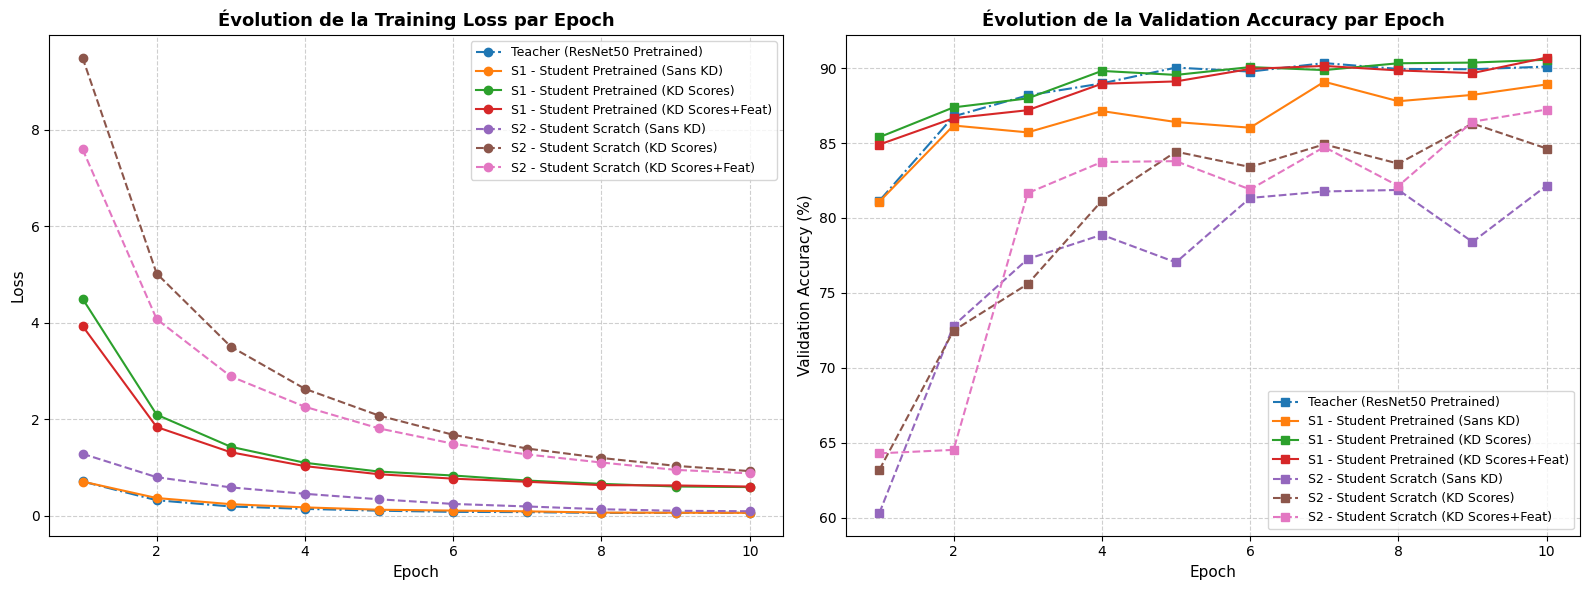


Graphique sauvegardé sur Drive : /content/drive/MyDrive/KD_CIFAR10_Checkpoints/comparaison_strategies_1_et_2.png


In [17]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

SAVE_DIR = "/content/drive/MyDrive/KD_CIFAR10_Checkpoints"

# 1. Liste des 7 modèles (Teacher + Stratégie 1 + Stratégie 2)
models_files = {
    "Teacher (ResNet50 Pretrained)": "teacher_history.json",
    "S1 - Student Pretrained (Sans KD)": "student_s1_base_history.json",
    "S1 - Student Pretrained (KD Scores)": "student_s1_scores_history.json",
    "S1 - Student Pretrained (KD Scores+Feat)": "student_s1_feat_history.json",
    "S2 - Student Scratch (Sans KD)": "student_s2_base_history.json",
    "S2 - Student Scratch (KD Scores)": "student_s2_scores_history.json",
    "S2 - Student Scratch (KD Scores+Feat)": "student_s2_feat_history.json",
}

histories = {}
for name, fname in models_files.items():
    path = os.path.join(SAVE_DIR, fname)
    if os.path.exists(path):
        with open(path, "r") as f:
            histories[name] = json.load(f)
    else:
        print(f"⚠️ Fichier non trouvé : {fname}")

# 2. Création et affichage du tableau récapitulatif
rows = []
for name, d in histories.items():
    avg_epoch_time = sum(d["epoch_time_sec"]) / len(d["epoch_time_sec"])
    rows.append({
        "Modèle": name,
        "Paramètres": f"{d['total_params']:,}",
        "Best Val Acc (%)": round(max(d["val_acc"]), 2),
        "Test Acc (%)": round(d["test_acc"], 2),
        "Temps moyen / Epoch (s)": round(avg_epoch_time, 2),
        "Temps Train Total (s)": round(d["total_train_time_sec"], 2),
        "Temps Inférence Test (s)": round(d["test_infer_time_sec"], 3)
    })

df_results = pd.DataFrame(rows)
print("=== TABLEAU COMPARATIF : TEACHER vs STRATÉGIE 1 vs STRATÉGIE 2 ===")
display(df_results)

# 3. Tracé des courbes de Loss et de Validation Accuracy pour chaque modèle
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, d in histories.items():
    epochs_range = range(1, len(d["train_loss"]) + 1)
    # Style différent pour distinguer visuellement Teacher, S1 (trait plein) et S2 (pointillés)
    linestyle = "--" if name.startswith("S2") else ("-." if name.startswith("Teacher") else "-")

    axes[0].plot(epochs_range, d["train_loss"], marker='o', linestyle=linestyle, label=name)
    axes[1].plot(epochs_range, d["val_acc"], marker='s', linestyle=linestyle, label=name)

# Graphique de gauche : Training Loss
axes[0].set_title("Évolution de la Training Loss par Epoch", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(fontsize=9)

# Graphique de droite : Validation Accuracy
axes[1].set_title("Évolution de la Validation Accuracy par Epoch", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation Accuracy (%)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(fontsize=9)

plt.tight_layout()
fig_path = os.path.join(SAVE_DIR, "comparaison_strategies_1_et_2.png")
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"\nGraphique sauvegardé sur Drive : {fig_path}")